In [61]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd, xarray as xr, scipy.stats as stats, json, scipy.optimize as op, pathlib, os, seaborn as sns
# plt.style.use('dark_background')

In [62]:
class ng_experiments:
    def __init__(self, df):
        expnum = df['expnum']
        self.input = df
        self.name = f'ng_5_{expnum}'
        self.date = df['date']
        
        self.rho = 995
        self.g = 9.81
        self.flow_width = 0.065 # m
        self.grain_diameter = 0.0041 # m
        self.rhos = 2471 # kg/m3
        self.LDA_x_loc = 2.2 # m
        
        if df['discharge']:
            self.discharge_height = df['discharge_height']
            self.discharge_time = df['discharge_time']
            self.discharge = self.discharge_calc()
        else: 
            self.discharge = np.nan
        
        self.feed_flux = (df['feeder_mass'] / df['feeder_times']).mean()
        self.vol_flux_per_width_feed = self.feed_flux / self.rhos / self.flow_width
        self.q8_feed = self.vol_flux_per_width_feed / np.sqrt(self.g * (self.rhos/self.rho - 1) * self.grain_diameter**3)
        
        self.ind_start = 1
        self.ind_end = 5
        try: 
            self.water_elev = df['water_elev']
            self.bed_elev = df['bed_elev']
            self.slope_calc()
        except:
            self.water_slope = np.nan
            self.bed_slope = np.nan
            self.tau8 = np.nan
            self.shear_stress = np.nan
        
        try:
            self.mass_flux_masses = df['mass_flux_mass'][df['mass_flux_range'][0]:df['mass_flux_range'][1]]
            self.mass_flux_times = df['mass_flux_times'][df['mass_flux_range'][0]:df['mass_flux_range'][1]]
            
            self.mass_flux = (self.mass_flux_masses /self.mass_flux_times).mean()
            self.mass_flux_last = np.mean((self.mass_flux_masses /self.mass_flux_times)[-3:-1])
            
            self.vol_flux_per_width = self.mass_flux / self.rhos / self.flow_width
            self.q8 = self.vol_flux_per_width / np.sqrt(self.g * (self.rhos/self.rho - 1) * self.grain_diameter**3)
        except:
            self.mass_flux = np.nan
            self.mass_flux_last = np.nan
            self.q8 = np.nan
        
        self.df = pd.DataFrame({'name': self.name, 'date': self.date, 'discharge': self.discharge, 'water_slope': self.water_slope, 'bed_slope': self.bed_slope, 'flow_depth': self.flow_depth, 'mass_flux': self.mass_flux, 'feed_flux': self.feed_flux, 'shear_stress': self.shear_stress, 'reynolds_stress': np.nan, 'tau8': self.tau8, 'q8': self.q8, 'q8_feed': self.q8_feed}, index=[0])
            
        
    def discharge_calc(self):
        # Bucket calibration is used to measure water flux from flume
        h = np.array([np.array([17.9,  17.8, 17.8, 17.85]).mean(),
                    np.array([17.7,  17.6, 17.8, 17.6]).mean(),
                    np.array([19.75, 19.8, 19.8, 19.8]).mean(),
                    np.array([19.9,  19.9, 19.9, 19.85]).mean(),
                    np.array([21.0,  21.1, 21.0, 21.0]).mean(),
                    np.array([21.8,  21.9, 21.8, 21.8]).mean()]).astype(float) # cm
        vol = np.array([10.0, 10.0, 11.25, 11.25, 12.0, 12.5]) # L
        plt.plot(h, vol, 'ko')

        def depth_vol(x, m, b):
            return m*x + b

        (bucket_m, bucket_b), non = op.curve_fit(depth_vol, h, vol)
        # x = np.linspace(15, 25, 100)
        # plt.plot(x, depth_vol(x, bucket_m, bucket_b), 'r')

        def discharge_func(h, t):
            if np.isnan(h).any():
                return np.nan

            elif np.isnan(t).any():
                    return np.nan
            else:
                return depth_vol(h*100, bucket_m, bucket_b) / t
            
        return discharge_func(self.discharge_height, self.discharge_time)
                
                
    def slope_calc(self):
        self.distance_from_upstream_end = np.array([100, 150, 200, 250, 300, 350]) / 100 # m
        self.thickness_of_pink_foam = np.array([5.1, 5.1, 5.1, 5.2, 5.2, 5.2]) / 100 # m
        self.elevation_above_flume_deck = np.array([22.4, 23.3, 24.2, 25.0, 25.8, 26.7]) / 100 # m

        slope, intercept, r_value, p_value, std_err = stats.linregress(self.distance_from_upstream_end, self.elevation_above_flume_deck)
        self.flume_bed_slope = np.degrees(np.arctan(slope))
    
        self.flow_depth = np.mean(self.water_elev[self.ind_start:self.ind_end] - self.bed_elev[self.ind_start:self.ind_end]) # m
        bed_surface = self.thickness_of_pink_foam[self.ind_start:self.ind_end] - self.elevation_above_flume_deck[self.ind_start:self.ind_end] + self.bed_elev[self.ind_start:self.ind_end]
        slope, intercept, r_value, p_value, std_err = stats.linregress(self.distance_from_upstream_end[self.ind_start:self.ind_end], bed_surface)
        self.bed_slope = -np.degrees(np.arctan(slope))

        water_surface = self.thickness_of_pink_foam[self.ind_start:self.ind_end] - self.elevation_above_flume_deck[self.ind_start:self.ind_end] + self.water_elev[self.ind_start:self.ind_end]
        print(water_surface)
        slope, intercept, r_value, p_value, std_err = stats.linregress(self.distance_from_upstream_end[self.ind_start:self.ind_end], water_surface)
        self.water_slope = -np.degrees(np.arctan(slope))
        
        self.hydrad = self.flow_depth * self.flow_width / (2 * self.flow_depth + self.flow_width) # m
        self.shear_stress = self.rho * self.g * self.hydrad * np.tan(np.radians(self.water_slope))
        self.tau8 = self.shear_stress / self.rho / self.g / (self.rhos/self.rho - 1) / self.grain_diameter
        
        func = lambda x, m, b: m*x + b
        (bed_m, bed_b), non = op.curve_fit(func, self.distance_from_upstream_end, self.elevation_above_flume_deck.max() - self.elevation_above_flume_deck + self.thickness_of_pink_foam + self.bed_elev)
        self.bed_elev_loc_LDA = func(self.LDA_x_loc, bed_m, bed_b)
        (foam_m, foam_b), non = op.curve_fit(func, self.distance_from_upstream_end, self.elevation_above_flume_deck.max() - self.elevation_above_flume_deck + self.thickness_of_pink_foam)
        self.foam_base_loc_LDA = func(self.LDA_x_loc, foam_m, foam_b)
        self.bed_ref_LDA = self.bed_elev_loc_LDA - self.foam_base_loc_LDA
        

    def plot_bed_slope(self):
        plt.figure(figsize=(8, 1.5))
        x = self.distance_from_upstream_end.max() - self.distance_from_upstream_end
        flume = self.elevation_above_flume_deck.max() - self.elevation_above_flume_deck
        foam = flume + self.thickness_of_pink_foam
        bed = flume + self.thickness_of_pink_foam + self.bed_elev
        water = flume + self.thickness_of_pink_foam + self.water_elev
        plt.plot(x, flume, 'k')
        plt.plot(x, foam, 'm')
        plt.plot(x, bed, 'ro--')
        plt.plot(x, water, 'bo--')
        x_plot = np.linspace(x[self.ind_start], x[self.ind_end-1], 100)
        y = np.tan(np.radians(self.bed_slope)) * (x_plot - x[3]) + bed[3]
        plt.plot(x_plot, y, 'r-')
        
        y = np.tan(np.radians(self.water_slope)) * (x_plot - x[3]) + water[3]
        plt.plot(x_plot, y, 'b-')
        
        plt.plot(self.distance_from_upstream_end.max() - self.LDA_x_loc, self.bed_elev_loc_LDA, 'ko')
        plt.plot(self.distance_from_upstream_end.max() - self.LDA_x_loc, self.foam_base_loc_LDA, 'ko')
        

        plt.xlim(0, 2.5)
        plt.ylim(0, 0.3)
        sns.despine()


    def plot_mass_flux(self):
        plt.figure(figsize=(8, 1.5))
        n = len(self.mass_flux_times)
        plt.plot(self.input['t_step'] * np.arange(n), self.mass_flux_masses/self.mass_flux_times * 1000, 'ro')
        plt.plot(self.input['t_step'] * np.arange(n), self.feed_flux.mean() * 1000 * np.ones(n), 'b--')
        plt.xlim(0, np.ceil(self.input['t_step'] * n))
        plt.ylim(0, np.ceil(1.1*self.feed_flux.mean() * 1000))
        sns.despine()
        
ng5 = [[], [], [], [], []]

### ng_5_01

[-0.05  -0.064 -0.077 -0.091]


/Users/ericdeal/anaconda3/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/ericdeal/anaconda3/lib/python3.11/site-packages/numpy/core/_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


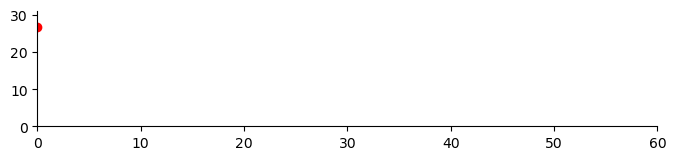

In [63]:
ng_5_01 = {
        'expnum': 1,
        'date': '30_11_2023',
        # feeder measurements
        'feeder_one_height': 17.2, # cm
        'feeder_two_height': 17.2, # cm
        'feeder_times': np.array([15.25, 15.44, 16.28]), # s
        'feeder_mass': np.array([408.09, 450.00, 460.58]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([9.5, 8.3, 7.7, 7.1, 6.4, 6.0]) / 100, # m
        'water_elev': np.array([14.6, 13.2, 12.7, 12.1, 11.5, 10.9]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([10, 11]),
        'mass_flux_times': np.array([10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10]), # s
        'mass_flux_mass': np.array([77.89, 100.32, 141.56, 138.82, 159.75, 177.55, 176.16, 189.99, 214.80, 205.23, 265.13, 226.99]) / 1000, # kg
        't_step': 60, # s
        }

ng5[0] = ng_experiments(ng_5_01)
ng5[0].plot_mass_flux()

### ng_5_02

[-0.08  -0.09  -0.095 -0.104]


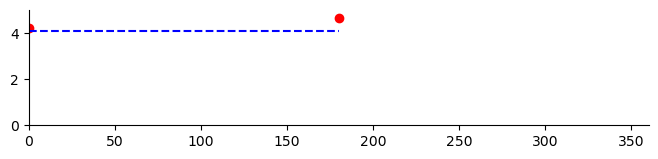

In [64]:
ng_5_02 = {
        'expnum': 2,
        'date': '30_11_2023',
        # feeder measurements
        'feeder_one_height': 6.5, # cm
        'feeder_two_height': np.nan, # cm
        'feeder_times': np.array([20, 20, 20]), # s
        'feeder_mass': np.array([81.94, 81.22, 82.21]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([5.0, 4.9, 4.75, 4.9, 4.9, 5.0]) / 100, # m
        'water_elev': np.array([10.5, 10.2, 10.1, 10.3, 10.2, 10.3]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([2, 4]),
        'mass_flux_times': np.array([30, 30, 30, 30, 30, 30]), # s
        'mass_flux_mass': np.array([101.38, 104.43, 126.94, 138.72, 137.89, 158.72]) / 1000, # kg
        't_step': 180, # s
        }

ng5[1] = ng_experiments(ng_5_02)
ng5[1].plot_mass_flux()

### ng_5_03

[-0.087 -0.093 -0.099 -0.109]


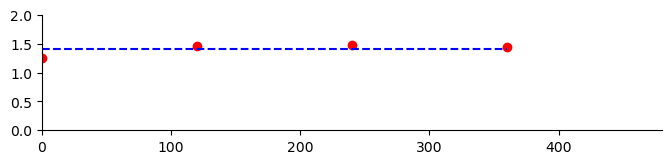

In [65]:
ng_5_03 = {
        'expnum': 3,
        'date': '1_12_2023',
        # feeder measurements
        'feeder_one_height': 2.0, # cm
        'feeder_two_height': np.nan, # cm
        'feeder_times': np.array([60.26]), # s
        'feeder_mass': np.array([84.63]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([4.3, 4.0, 4.4, 4.6, 4.4, 4.8]) / 100, # m
        'water_elev': np.array([9.9, 9.5, 9.8, 9.9, 9.7, 10.3]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([1, 5]),
        'mass_flux_times': np.array([120, 120, 120, 120, 120, 120]), # s
        # 'mass_flux_mass': np.array([174.36, 150.21, 109.13, 177.23, 173.22, 141.36]) / 1000, # kg
        'mass_flux_mass': np.array([109.13, 150.21, 174.36, 177.23, 173.22, 141.36]) / 1000, # kg
        't_step': 120, # s
        }
ng5[2] = ng_experiments(ng_5_03)
ng5[2].plot_mass_flux()

### ng_5_04

[-0.058 -0.071 -0.086 -0.095]


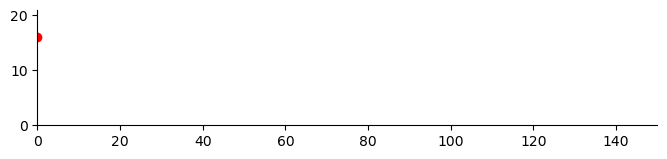

In [66]:
ng_5_04 = {
        'expnum': 4,
        'date': '1_12_2023',
        # feeder measurements
        'feeder_one_height': 13.0, # cm
        'feeder_two_height': 13.0, # cm
        'feeder_times': np.array([45.0, 29.89]), # s
        'feeder_mass': np.array([830.54, 546.61]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([8.6, 7.9, 7.5, 6.8, 6.4, 5.9]) / 100, # m
        'water_elev': np.array([13.3, 12.4, 12.0, 11.2, 11.1, 11.1]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([5, 6]),
        'mass_flux_times': np.array([30, 30, 30, 30, 30, 30, 30]), # s
        'mass_flux_mass': np.array([317.35, 363.46, 399.56, 419.06, 444.91, 483.13, 494.50]) / 1000, # kg
        't_step': 150, # s
        }

ng5[3] = ng_experiments(ng_5_04)
ng5[3].plot_mass_flux()

### ng_5_05

[-0.07  -0.081 -0.09  -0.103]


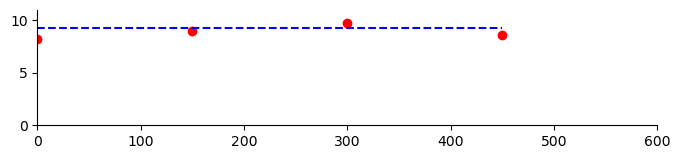

In [67]:
ng_5_05 = {
        'expnum': 5,
        'date': '2_12_2023',
        # feeder measurements
        'feeder_one_height': 7.5, # cm
        'feeder_two_height': 7.5, # cm
        'feeder_times': np.array([30.48]), # s
        'feeder_mass': np.array([283.24]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([6.8, 6.1, 6.0, 5.8, 5.4, 5.3]) / 100, # m
        'water_elev': np.array([11.7, 11.2, 11.0, 10.8, 10.3, 10.2]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([4, 8]),
        'mass_flux_times': np.array([30, 30, 30, 30, 30, 30, 30, 30, 30]), # s
        'mass_flux_mass': np.array([231.69, 208.44, 200.14, 205.93, 245.58, 268.31, 292.23, 259.00, 266.11]) / 1000, # kg
        't_step': 150, # s
        }

ng5[4] = ng_experiments(ng_5_05)
ng5[4].plot_mass_flux()

In [68]:
ng_5s = pd.concat([ng5[i].df for i in [0, 1, 2, 3, 4]])
ng_5s.to_csv('ng_5_data.csv', index=False)
ng_5s

,name,date,discharge,water_slope,bed_slope,flow_depth,mass_flux,feed_flux,shear_stress,reynolds_stress,tau8,q8,q8_feed
0,ng_5_1,30_11_2023,NaN,1.558061,1.626763,0.050000,0.026513,0.028065,5.229503,NaN,0.088089,0.164828,0.174479
0,ng_5_2,30_11_2023,NaN,0.882285,0.888013,0.053375,0.004428,0.004090,3.036458,NaN,0.051148,0.027526,0.025424
0,ng_5_3,1_12_2023,NaN,0.825002,0.744803,0.053750,0.001406,0.001404,2.846802,NaN,0.047953,0.008743,0.008731
0,ng_5_4,1_12_2023,NaN,1.443548,1.500806,0.045250,0.016104,0.018372,4.652583,NaN,0.078371,0.100119,0.114216
0,ng_5_5,2_12_2023,NaN,1.237396,1.168672,0.050000,0.008876,0.009293,4.152841,NaN,0.069953,0.055181,0.057771


0.07568000000681921
0.049079047625203515
0.04405523809533429
0.07236761904777667
0.05928000000653039


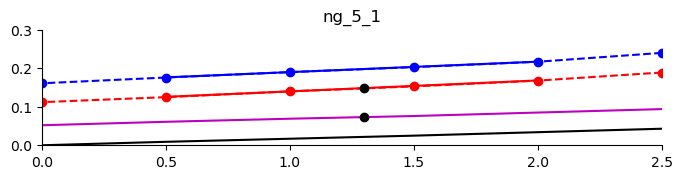

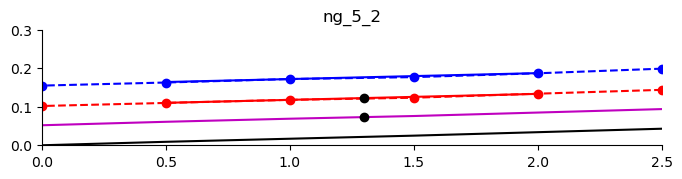

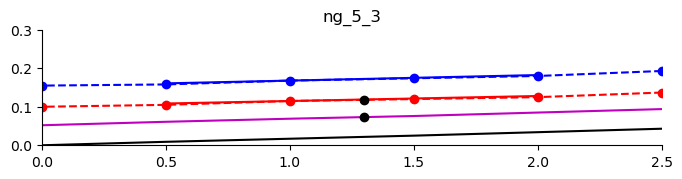

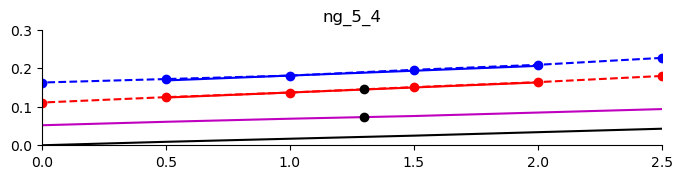

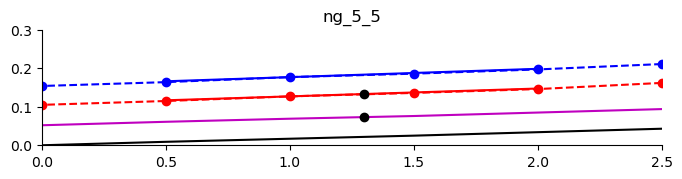

In [69]:
for ng in ng5:
    ng.plot_bed_slope()
    print(ng.bed_ref_LDA)
    plt.title(ng.name)

In [70]:
for i in range(len(ng5)):
    # plt.figure(i)
    vdata = np.array(list(pathlib.Path(f'/Users/ericdeal/Documents/1_eth/1_projects/grain_shape/2023_experiments/ng_exps/velocity_data/Narrow_Flume_Ng_5_0{i+1}').glob('*_Coincident*.csv')))
    vdata = vdata[np.argsort([int(name.stem.split('Ng')[1].split('_')[3][1]) for name in vdata])]

    reynolds_stress = np.zeros(len(vdata))
    mean_vel = np.zeros(len(vdata))
    heights = np.zeros(len(vdata))
    for j in range(len(vdata)):
        df = pd.read_csv(vdata[j], header=1)

        u = df[' \"Velocity Ch. 1 (m/sec)\"'].values
        v = df[' \"Velocity Ch. 2 (m/sec)\"'].values
        mean_vel[j] = np.sqrt((u.mean()**2 + v.mean())**2)
        reynolds_stress[j] = np.mean((u - u.mean()) * (v - v.mean()))
        
        heights[j] = float(df[' \"Y Axis Position\"'].values[0]) - ng5[i].bed_ref_LDA*1000
        
    reynolds_stress = reynolds_stress[np.argsort(heights)][::-1]
    mean_vel = mean_vel[np.argsort(heights)][::-1]
    heights = heights[np.argsort(heights)][::-1]
    lower_depth_threshold = 0
    reynolds_stress = reynolds_stress[heights >= lower_depth_threshold]
    mean_vel = mean_vel[heights >= lower_depth_threshold]
    heights = heights[heights >= lower_depth_threshold]
    
    pd.DataFrame({'y': heights, 'reynolds_stress': reynolds_stress, 'mean_vel': mean_vel}).to_csv(f'velocity_data/ng_5_{i+1}_LDA_data_processed.csv', index=False)